In [2]:
print("CNN Project Started")

CNN Project Started


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)


NumPy: 2.5.3
Pandas: 3.0.5
PyTorch: 2.14.0+cpu
Torchvision: 0.29.0+cpu


In [4]:
import os
from PIL import Image

DATASET = "dataset_split"

valid_extensions = (".jpg", ".jpeg", ".png")
corrupted_images = []
invalid_files = []

# Check all train, validation and test folders
for split in ["train", "val", "test"]:
    split_path = os.path.join(DATASET, split)

    for class_name in os.listdir(split_path):
        class_path = os.path.join(split_path, class_name)

        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):
            filepath = os.path.join(class_path, filename)

            # Check file extension
            if not filename.lower().endswith(valid_extensions):
                invalid_files.append(filepath)
                continue

            # Check whether image can be opened
            try:
                with Image.open(filepath) as img:
                    img.verify()
            except Exception:
                corrupted_images.append(filepath)

print("DATA CLEANING RESULTS")
print("----------------------")
print("Invalid files:", len(invalid_files))
print("Corrupted images:", len(corrupted_images))

DATA CLEANING RESULTS
----------------------
Invalid files: 0
Corrupted images: 0


In [5]:
import os

DATASET = "dataset_split"

for split in ["train", "val", "test"]:
    split_path = os.path.join(DATASET, split)

    print("\n" + "=" * 30)
    print(split.upper())
    print("=" * 30)

    total = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])

            print(f"{class_name}: {count}")
            total += count

    print(f"Total {split} images: {total}")


TRAIN
Bear: 87
Bird: 95
Cat: 86
Cow: 91
Deer: 88
Dog: 85
Dolphin: 90
Elephant: 93
Giraffe: 90
Horse: 91
Kangaroo: 88
Lion: 91
Panda: 94
Tiger: 90
Zebra: 95
Total train images: 1354

VAL
Bear: 18
Bird: 20
Cat: 18
Cow: 19
Deer: 19
Dog: 18
Dolphin: 19
Elephant: 19
Giraffe: 19
Horse: 19
Kangaroo: 18
Lion: 19
Panda: 20
Tiger: 19
Zebra: 20
Total val images: 284

TEST
Bear: 20
Bird: 22
Cat: 19
Cow: 21
Deer: 20
Dog: 19
Dolphin: 20
Elephant: 21
Giraffe: 20
Horse: 20
Kangaroo: 20
Lion: 21
Panda: 21
Tiger: 20
Zebra: 22
Total test images: 306


In [6]:
import os
from PIL import Image

DATASET = "dataset_split"

sizes = {}

for split in ["train", "val", "test"]:
    split_path = os.path.join(DATASET, split)

    for class_name in os.listdir(split_path):
        class_path = os.path.join(split_path, class_name)

        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):

            if filename.lower().endswith((".jpg", ".jpeg", ".png")):

                filepath = os.path.join(class_path, filename)

                try:
                    with Image.open(filepath) as img:
                        size = img.size
                        sizes[size] = sizes.get(size, 0) + 1

                except:
                    pass

print("Different image sizes found:")
print("---------------------------")

for size, count in sorted(sizes.items(), key=lambda x: x[1], reverse=True):
    print(size, "→", count, "images")
    

Different image sizes found:
---------------------------
(224, 224) → 1944 images


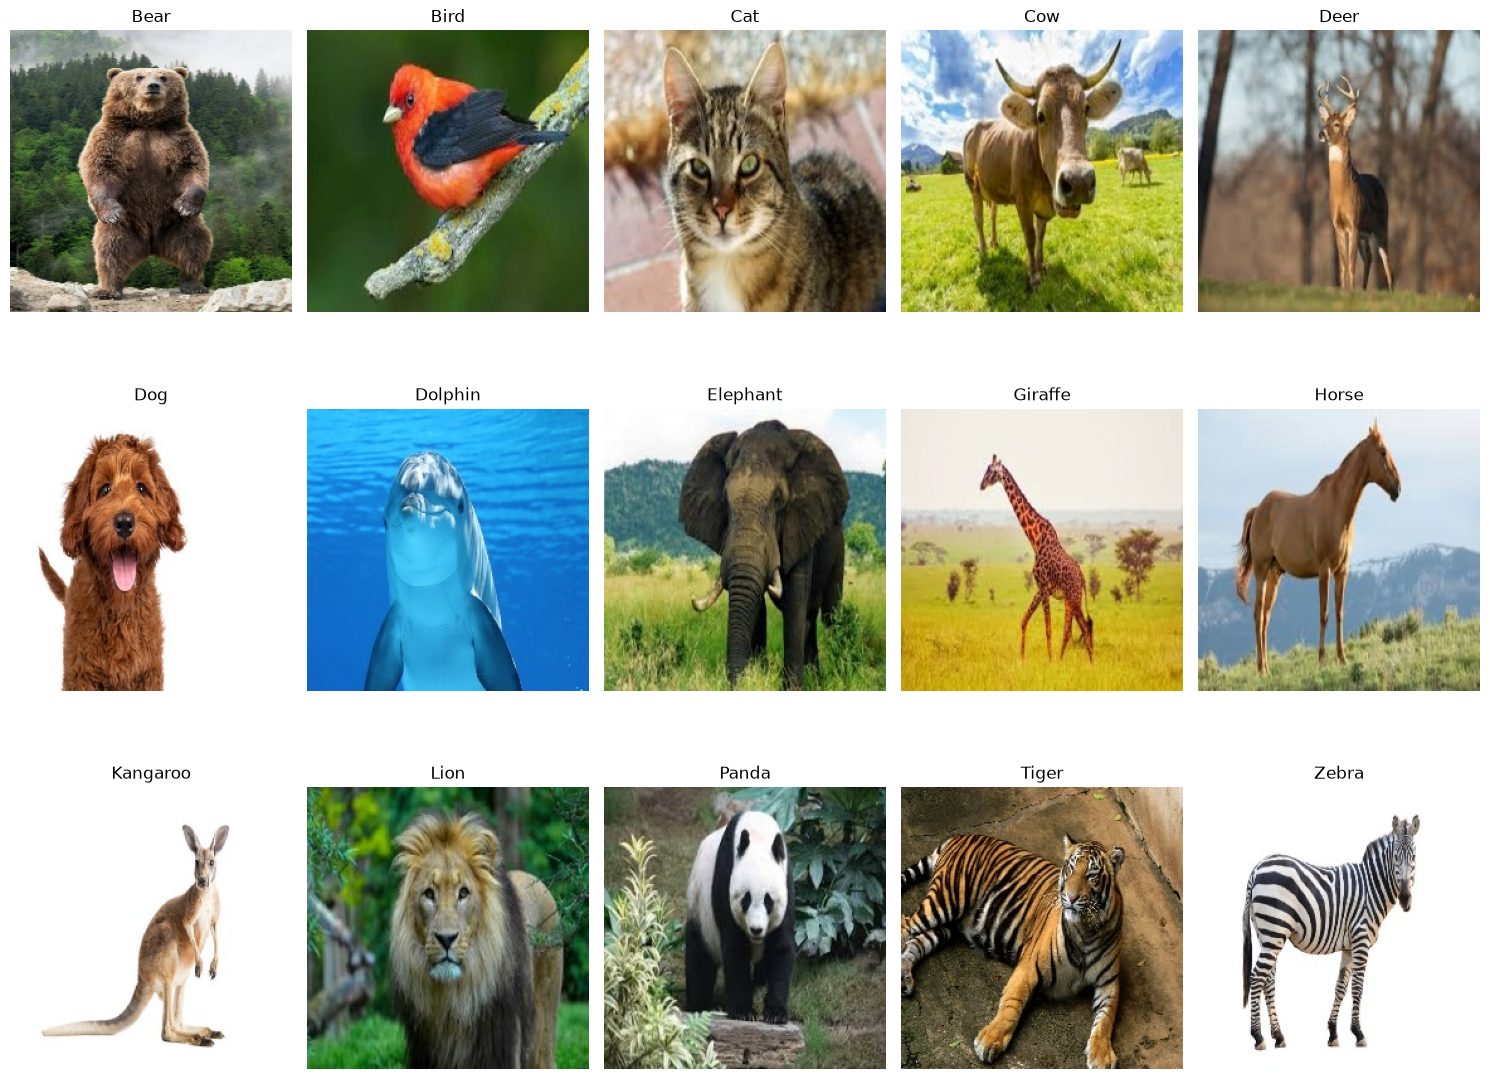

In [7]:
import matplotlib.pyplot as plt
import os
from PIL import Image

DATASET = "dataset_split/train"

classes = sorted(os.listdir(DATASET))

plt.figure(figsize=(15, 12))

for i, class_name in enumerate(classes):
    class_path = os.path.join(DATASET, class_name)
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    img = Image.open(image_path)

    plt.subplot(3, 5, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

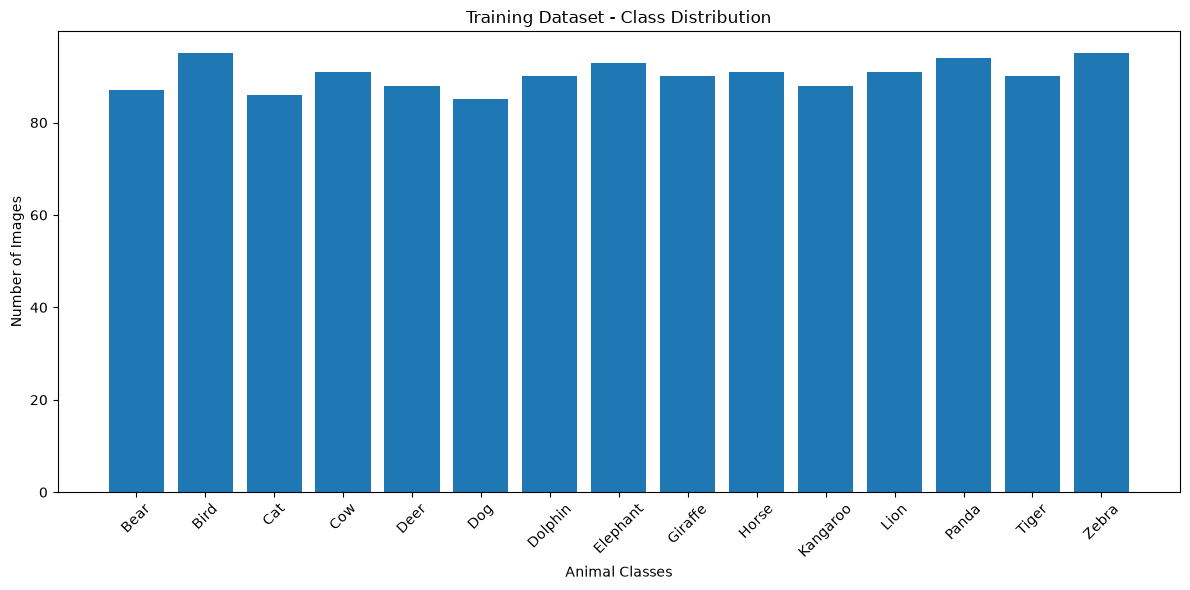

In [8]:
import os
import matplotlib.pyplot as plt

DATASET = "dataset_split/train"

classes = sorted(os.listdir(DATASET))
counts = []

for class_name in classes:
    class_path = os.path.join(DATASET, class_name)
    count = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    counts.append(count)

plt.figure(figsize=(12, 6))
plt.bar(classes, counts)

plt.xlabel("Animal Classes")
plt.ylabel("Number of Images")
plt.title("Training Dataset - Class Distribution")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


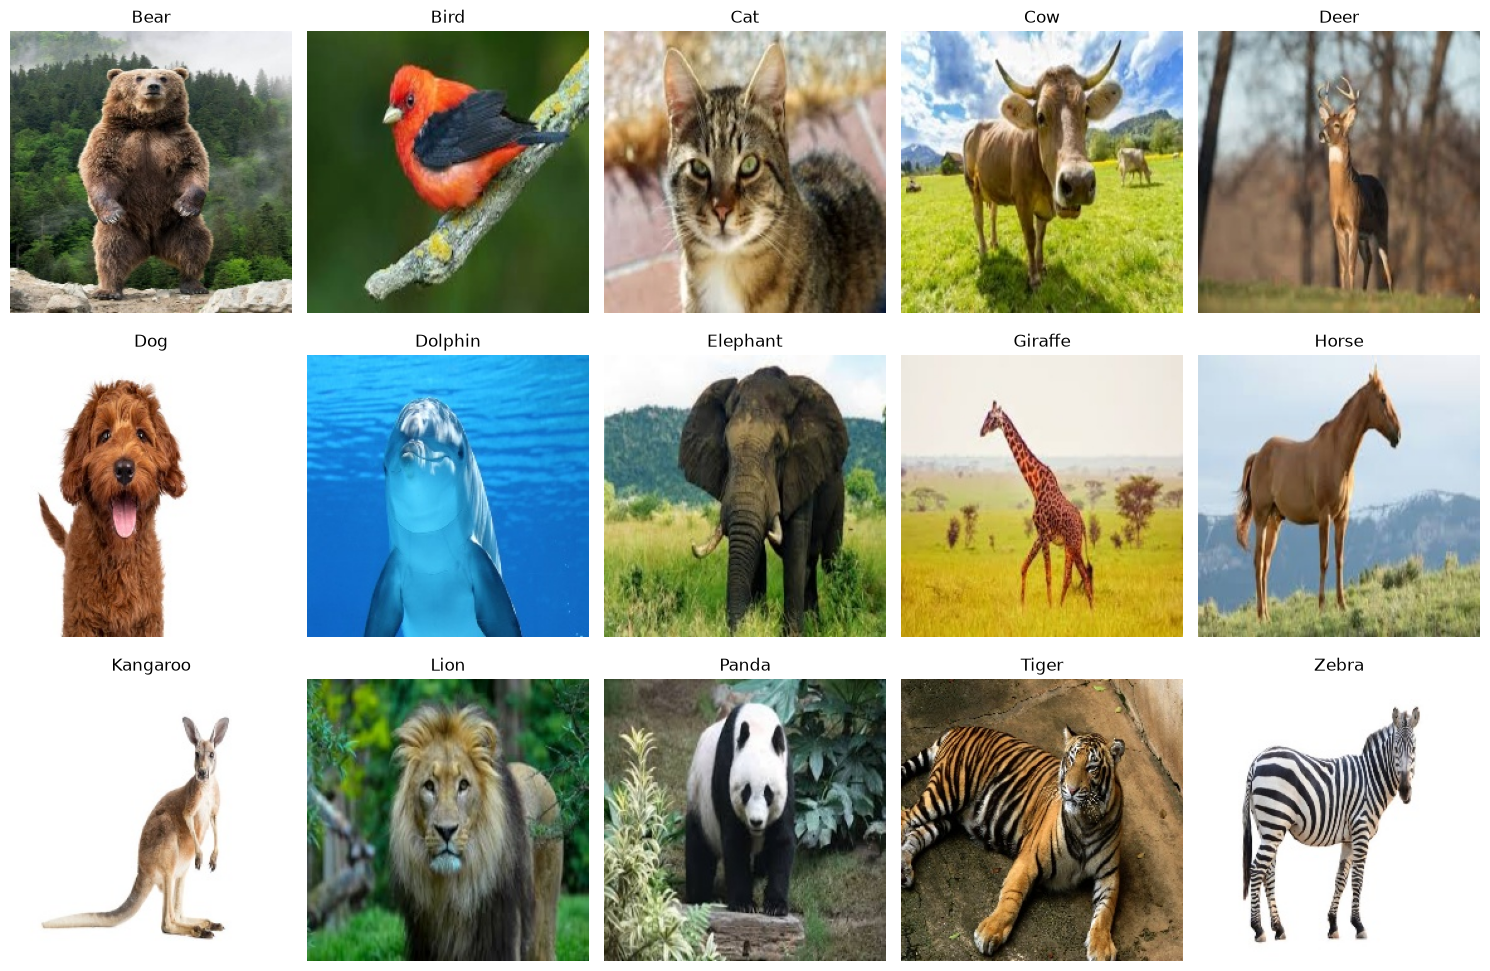

In [9]:
import matplotlib.pyplot as plt
import os
from PIL import Image

DATASET = "dataset_split/train"

classes = sorted(os.listdir(DATASET))

plt.figure(figsize=(15, 10))

for i, class_name in enumerate(classes):
    class_path = os.path.join(DATASET, class_name)
    
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)
    
    img = Image.open(image_path)

    plt.subplot(3, 5, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:

from PIL import Image
import os

image_path = os.path.join(
    "dataset_split", "train", "Bear", os.listdir("dataset_split/train/Bear")[0]
)

img = Image.open(image_path)

print("Image size:", img.size)
print("Image mode:", img.mode)

Image size: (224, 224)
Image mode: RGB


In [11]:
import numpy as np
from PIL import Image
import os

DATASET = "dataset_split/train"

pixel_values = []

for class_name in os.listdir(DATASET):
    class_path = os.path.join(DATASET, class_name)

    for filename in os.listdir(class_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(class_path, filename)

            img = Image.open(image_path).convert("RGB")
            arr = np.array(img)

            pixel_values.append(arr.mean())

print("Average pixel value:", np.mean(pixel_values))


Average pixel value: 98.83265874579382


In [12]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATASET = "dataset_split"

# Preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Load datasets
train_data = datasets.ImageFolder(
    DATASET + "/train",
    transform=transform
)

val_data = datasets.ImageFolder(
    DATASET + "/val",
    transform=transform
)

test_data = datasets.ImageFolder(
    DATASET + "/test",
    transform=transform
)

# Create loaders
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))
print("Classes:", train_data.classes)

Training images: 1354
Validation images: 284
Test images: 306
Classes: ['Bear', 'Bird', 'Cat', 'Cow', 'Deer', 'Dog', 'Dolphin', 'Elephant', 'Giraffe', 'Horse', 'Kangaroo', 'Lion', 'Panda', 'Tiger', 'Zebra']


In [13]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel value range:", images.min().item(), "to", images.max().item())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Pixel value range: 0.0 to 1.0


In [14]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

print("Data augmentation is ready.")


Data augmentation is ready.


In [15]:
from torchvision import datasets
from torch.utils.data import DataLoader

DATASET = "dataset_split"

train_data = datasets.ImageFolder(
    DATASET + "/train",
    transform=train_transform
)

val_data = datasets.ImageFolder(
    DATASET + "/val",
    transform=val_test_transform
)

test_data = datasets.ImageFolder(
    DATASET + "/test",
    transform=val_test_transform
)

train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=32,
    shuffle=False
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))
print("Data augmentation applied to training data.")


Training images: 1354
Validation images: 284
Test images: 306
Data augmentation applied to training data.


In [39]:
import torch
import torch.nn as nn


class VGG7(nn.Module):
    def __init__(self, num_classes=15):
        super(VGG7, self).__init__()

        # Block 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        # Block 2
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)

        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(64)

        # Block 3
        self.conv5 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(128)

        self.conv6 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn6 = nn.BatchNorm2d(128)

        # Max pooling
        self.pool = nn.MaxPool2d(2, 2)

        # Reduce 28x28 feature maps to 4x4
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        # 128 * 4 * 4 = 2048 instead of 128 * 28 * 28 = 100352
        self.fc = nn.Linear(128 * 4 * 4, num_classes)

        self.dropout = nn.Dropout(0.5)

    def forward(self, x):

        # Block 1
        x = torch.relu(self.bn1(self.conv1(x)))
        x = torch.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        # Block 2
        x = torch.relu(self.bn3(self.conv3(x)))
        x = torch.relu(self.bn4(self.conv4(x)))
        x = self.pool(x)

        # Block 3
        x = torch.relu(self.bn5(self.conv5(x)))
        x = torch.relu(self.bn6(self.conv6(x)))
        x = self.pool(x)

        # Adaptive pooling
        x = self.adaptive_pool(x)

        # Flatten
        x = torch.flatten(x, 1)

        # Dropout + classification
        x = self.dropout(x)
        x = self.fc(x)

        return x


# Create a fresh model
model = VGG7(num_classes=15)
model = model.to(device)

print(model)

VGG7(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv6): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn6): BatchNorm2d(128, eps

In [42]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("New lightweight VGG7 and optimizer ready!")

New lightweight VGG7 and optimizer ready!


In [43]:
model.eval()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Test successful!")

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 15])
Test successful!


In [44]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 43
Validation batches: 9
Test batches: 10


In [45]:
import torch

# Train for 1 epoch
model.train()

running_loss = 0.0
correct = 0
total = 0

for batch_idx, (images, labels) in enumerate(train_loader):

    images = images.to(device)
    labels = labels.to(device)

    # Clear previous gradients
    optimizer.zero_grad()

    # Forward pass
    outputs = model(images)

    # Calculate loss
    loss = criterion(outputs, labels)

    # Backpropagation
    loss.backward()

    # Update weights
    optimizer.step()

    # Statistics
    running_loss += loss.item()

    _, predicted = torch.max(outputs, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

    # Show progress
    if (batch_idx + 1) % 5 == 0:
        print(
            f"Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

train_accuracy = 100 * correct / total
average_loss = running_loss / len(train_loader)

print("\n1 Epoch Training Complete!")
print(f"Train Loss: {average_loss:.4f}")
print(f"Train Accuracy: {train_accuracy:.2f}%")

Batch [5/43] Loss: 3.2121
Batch [10/43] Loss: 2.4060
Batch [15/43] Loss: 2.8040
Batch [20/43] Loss: 2.2843
Batch [25/43] Loss: 2.5353
Batch [30/43] Loss: 2.5559
Batch [35/43] Loss: 2.3609
Batch [40/43] Loss: 2.3773

1 Epoch Training Complete!
Train Loss: 2.6189
Train Accuracy: 18.24%


In [20]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

model = model.to(device)

Device: cpu


Epoch [1/1] Train Loss: 16.4877 Train Accuracy: 12.56% Val Loss: 5.1752 Val Accuracy: 9.51%


Epoch [1/10] Train Loss: 2.7223 Train Accuracy: 5.32% Val Loss: 2.7080 Val Accuracy: 7.04%
Epoch [2/10] Train Loss: 2.7082 Train Accuracy: 6.20% Val Loss: 2.7079 Val Accuracy: 7.04%
Epoch [3/10] Train Loss: 2.7081 Train Accuracy: 6.50% Val Loss: 2.7078 Val Accuracy: 7.04%
Epoch [4/10] Train Loss: 2.7080 Train Accuracy: 6.43% Val Loss: 2.7077 Val Accuracy: 7.04%
Epoch [5/10] Train Loss: 2.7080 Train Accuracy: 7.02% Val Loss: 2.7076 Val Accuracy: 7.04%
Epoch [6/10] Train Loss: 2.7081 Train Accuracy: 6.65% Val Loss: 2.7076 Val Accuracy: 7.04%
Epoch [7/10] Train Loss: 2.7079 Train Accuracy: 6.13% Val Loss: 2.7076 Val Accuracy: 7.04%
Epoch [8/10] Train Loss: 2.7077 Train Accuracy: 7.02% Val Loss: 2.7075 Val Accuracy: 7.04%
Epoch [9/10] Train Loss: 2.7080 Train Accuracy: 7.02% Val Loss: 2.7074 Val Accuracy: 7.04%
Epoch [10/10] Train Loss: 2.7079 Train Accuracy: 5.83% Val Loss: 2.7074 Val Accuracy: 7.04%


In [22]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Optimizer reset successfully.")

Optimizer reset successfully.


In [24]:
print("Number of classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

NameError: name 'train_dataset' is not defined

In [25]:
train_dataset = datasets.ImageFolder(...)
val_dataset = datasets.ImageFolder(...)

TypeError: scandir: path should be string, bytes, os.PathLike or None, not ellipsis

In [26]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFolders/files here:")
print(os.listdir())

Current folder:
c:\Users\DELL\Downloads\cnn_project

Folders/files here:
['cnn_env', 'cnn_envcnn_env', 'CNN_Project.ipynb', 'dataset', 'dataset_split', 'models', 'notebooks', 'requirements.txt', 'split_dataset.py', 'src']


In [27]:
import os

print(os.listdir("dataset_split"))

['test', 'train', 'val']


In [28]:
from torchvision import datasets, transforms

train_dir = "dataset_split/train"
val_dir = "dataset_split/val"
test_dir = "dataset_split/test"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(train_dir, transform=transform)
val_dataset = datasets.ImageFolder(val_dir, transform=transform)
test_dataset = datasets.ImageFolder(test_dir, transform=transform)

print("Number of classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


Number of classes: 15
Classes: ['Bear', 'Bird', 'Cat', 'Cow', 'Deer', 'Dog', 'Dolphin', 'Elephant', 'Giraffe', 'Horse', 'Kangaroo', 'Lion', 'Panda', 'Tiger', 'Zebra']
Training images: 1354
Validation images: 284
Test images: 306


In [30]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 43
Validation batches: 9
Test batches: 10


In [31]:
print(model)

print("\nNumber of output classes:", model.fc.out_features)

VGG7(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv6): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=100352, out_features=15, bias=True)
)

Number of output classes: 15


In [32]:
import torch

images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("First 10 labels:", labels[:10])

with torch.no_grad():
    outputs = model(images)

print("Output shape:", outputs.shape)
print("First prediction:", outputs[0])

Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])
First 10 labels: tensor([14,  1,  0,  3, 10,  9,  2,  5,  0,  8])
Output shape: torch.Size([32, 15])
First prediction: tensor([-0.0170,  0.0236, -0.0265,  0.0023, -0.0127, -0.0307, -0.0042,  0.0129,
        -0.0030,  0.0033, -0.0107,  0.0031,  0.0211, -0.0070,  0.0274])


In [46]:
model.train()

running_loss = 0.0
correct = 0
total = 0

for batch_idx, (images, labels) in enumerate(train_loader):

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    optimizer.step()

    running_loss += loss.item()

    _, predicted = torch.max(outputs, 1)

    total += labels.size(0)
    correct += (predicted == labels).sum().item()

    if (batch_idx + 1) % 5 == 0:
        print(
            f"Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

train_loss = running_loss / len(train_loader)
train_accuracy = 100 * correct / total

print("\n1 Epoch Training Complete!")
print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_accuracy:.2f}%")

Batch [5/43] Loss: 1.9610
Batch [10/43] Loss: 2.2699
Batch [15/43] Loss: 2.1230
Batch [20/43] Loss: 1.9602
Batch [25/43] Loss: 2.6680
Batch [30/43] Loss: 2.0593
Batch [35/43] Loss: 2.0259
Batch [40/43] Loss: 2.1234

1 Epoch Training Complete!
Train Loss: 2.2334
Train Accuracy: 27.92%


In [47]:
model.eval()

correct = 0
total = 0
val_loss = 0.0

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)
        val_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

val_accuracy = 100 * correct / total
val_loss = val_loss / len(val_loader)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2f}%")

Validation Loss: 2.2790
Validation Accuracy: 30.63%


In [49]:
import torch

num_epochs = 10

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # --------------------
    # Validation
    # --------------------
    model.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 2.0352 Train Accuracy: 34.71% Val Loss: 1.9369 Val Accuracy: 35.56%
Epoch [2/10] Train Loss: 1.8258 Train Accuracy: 41.43% Val Loss: 1.8954 Val Accuracy: 41.20%
Epoch [3/10] Train Loss: 1.6922 Train Accuracy: 45.49% Val Loss: 1.8773 Val Accuracy: 40.49%
Epoch [4/10] Train Loss: 1.5744 Train Accuracy: 51.70% Val Loss: 1.7887 Val Accuracy: 42.61%
Epoch [5/10] Train Loss: 1.5051 Train Accuracy: 51.62% Val Loss: 1.7587 Val Accuracy: 46.13%
Epoch [6/10] Train Loss: 1.4215 Train Accuracy: 54.80% Val Loss: 1.7437 Val Accuracy: 41.90%
Epoch [7/10] Train Loss: 1.3005 Train Accuracy: 59.45% Val Loss: 1.4857 Val Accuracy: 48.59%
Epoch [8/10] Train Loss: 1.2599 Train Accuracy: 58.71% Val Loss: 1.6758 Val Accuracy: 49.30%
Epoch [9/10] Train Loss: 1.2657 Train Accuracy: 58.64% Val Loss: 1.5221 Val Accuracy: 51.06%
Epoch [10/10] Train Loss: 1.2062 Train Accuracy: 61.45% Val Loss: 1.6364 Val Accuracy: 49.30%


In [50]:
torch.save(model.state_dict(), "vgg7_epoch10.pth")
print("Model saved successfully!")


Model saved successfully!


In [1]:
import torch
import torch.nn as nn


class VGG7(nn.Module):
    def __init__(self, num_classes=15):
        super(VGG7, self).__init__()

        # Block 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        # Block 2
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)

        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(64)

        # Block 3
        self.conv5 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(128)

        self.conv6 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn6 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)

        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(128 * 4 * 4, num_classes)

    def forward(self, x):

        x = torch.relu(self.bn1(self.conv1(x)))
        x = torch.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        x = torch.relu(self.bn3(self.conv3(x)))
        x = torch.relu(self.bn4(self.conv4(x)))
        x = self.pool(x)

        x = torch.relu(self.bn5(self.conv5(x)))
        x = torch.relu(self.bn6(self.conv6(x)))
        x = self.pool(x)

        x = self.adaptive_pool(x)

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

print("VGG7 definition loaded!")

VGG7 definition loaded!


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [4]:
model = VGG7(num_classes=15)
model = model.to(device)

model.load_state_dict(
    torch.load("vgg7_epoch10.pth", map_location=device)
)

print("Epoch 10 model loaded successfully!")

Epoch 10 model loaded successfully!


In [5]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Data augmentation ready!")

Data augmentation ready!


In [6]:
from torchvision import datasets
from torch.utils.data import DataLoader

train_dataset = datasets.ImageFolder(
    "dataset_split/train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    "dataset_split/val",
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    "dataset_split/test",
    transform=eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("New DataLoaders created!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

New DataLoaders created!
Training batches: 43
Validation batches: 9
Test batches: 10


In [7]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0003
)

print("Optimizer ready!")
print("Learning rate: 0.0003")

Optimizer ready!
Learning rate: 0.0003


In [8]:
num_epochs = 10

for epoch in range(11, 21):

    # =========================
    # TRAINING
    # =========================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch [{epoch}/20] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [11/20] Train Loss: 1.4072 Train Accuracy: 56.35% Val Loss: 1.3474 Val Accuracy: 54.93%
Epoch [12/20] Train Loss: 1.3014 Train Accuracy: 58.20% Val Loss: 1.3476 Val Accuracy: 58.45%
Epoch [13/20] Train Loss: 1.2519 Train Accuracy: 59.97% Val Loss: 1.2251 Val Accuracy: 60.92%
Epoch [14/20] Train Loss: 1.2033 Train Accuracy: 62.11% Val Loss: 1.4502 Val Accuracy: 54.93%
Epoch [15/20] Train Loss: 1.1993 Train Accuracy: 62.04% Val Loss: 1.5014 Val Accuracy: 55.28%
Epoch [16/20] Train Loss: 1.1860 Train Accuracy: 62.92% Val Loss: 1.2566 Val Accuracy: 60.21%
Epoch [17/20] Train Loss: 1.1476 Train Accuracy: 63.52% Val Loss: 1.2329 Val Accuracy: 60.92%
Epoch [18/20] Train Loss: 1.1143 Train Accuracy: 63.00% Val Loss: 1.2282 Val Accuracy: 60.92%
Epoch [19/20] Train Loss: 1.0792 Train Accuracy: 65.73% Val Loss: 1.1794 Val Accuracy: 64.44%
Epoch [20/20] Train Loss: 1.0841 Train Accuracy: 64.84% Val Loss: 1.3139 Val Accuracy: 61.27%


In [9]:
torch.save(model.state_dict(), "vgg7_epoch20.pth")
print("Epoch 20 model saved successfully!")


Epoch 20 model saved successfully!


In [10]:
best_val_accuracy = 61.27

print("Best validation accuracy tracker set to:", best_val_accuracy)


Best validation accuracy tracker set to: 61.27


In [11]:
for epoch in range(21, 26):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # Validation
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    # Save best model
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "vgg7_best.pth"
        )

        print("⭐ Best model saved!")

    print(
        f"Epoch [{epoch}/30] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

print(f"\nBest Validation Accuracy: {best_val_accuracy:.2f}%")

⭐ Best model saved!
Epoch [21/30] Train Loss: 1.0569 Train Accuracy: 67.80% Val Loss: 1.1514 Val Accuracy: 65.85%
Epoch [22/30] Train Loss: 1.0888 Train Accuracy: 66.25% Val Loss: 1.2013 Val Accuracy: 63.38%
⭐ Best model saved!
Epoch [23/30] Train Loss: 1.0116 Train Accuracy: 67.43% Val Loss: 1.1244 Val Accuracy: 66.55%
Epoch [24/30] Train Loss: 1.0096 Train Accuracy: 67.73% Val Loss: 1.1041 Val Accuracy: 65.14%
Epoch [25/30] Train Loss: 1.0154 Train Accuracy: 68.61% Val Loss: 1.1114 Val Accuracy: 65.85%

Best Validation Accuracy: 66.55%


In [12]:
import os

print(os.path.exists("vgg7_best.pth"))

True


In [13]:
# Train Epochs 26 to 30

best_val_accuracy = 66.55

for epoch in range(26, 31):

    # ---------------- TRAINING ----------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # ---------------- VALIDATION ----------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    # ---------------- SAVE BEST MODEL ----------------
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(model.state_dict(), "vgg7_best.pth")

        print("⭐ Best model saved!")

    print(
        f"Epoch [{epoch}/30] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

print(f"\n🏆 Best Validation Accuracy: {best_val_accuracy:.2f}%")

Epoch [26/30] Train Loss: 1.0007 Train Accuracy: 69.13% Val Loss: 1.1861 Val Accuracy: 65.49%
⭐ Best model saved!
Epoch [27/30] Train Loss: 0.9902 Train Accuracy: 67.06% Val Loss: 1.0630 Val Accuracy: 67.25%
Epoch [28/30] Train Loss: 0.9835 Train Accuracy: 68.83% Val Loss: 1.2008 Val Accuracy: 64.79%
Epoch [29/30] Train Loss: 0.9820 Train Accuracy: 68.32% Val Loss: 1.1674 Val Accuracy: 65.49%
⭐ Best model saved!
Epoch [30/30] Train Loss: 1.0125 Train Accuracy: 67.80% Val Loss: 1.0576 Val Accuracy: 67.61%

🏆 Best Validation Accuracy: 67.61%


In [14]:
torch.save(model.state_dict(), "vgg7_best.pth")
print("Best model (Epoch 30) saved successfully!")

Best model (Epoch 30) saved successfully!


In [15]:
best_val_accuracy = 67.61

for epoch in range(31, 36):

    # TRAIN
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # VALIDATION
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    # SAVE ONLY IF BETTER
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(), "vgg7_best.pth")
        print("⭐ Best model saved!")

    print(
        f"Epoch [{epoch}/35] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

print(f"\n🏆 Best Validation Accuracy: {best_val_accuracy:.2f}%")

⭐ Best model saved!
Epoch [31/35] Train Loss: 0.9205 Train Accuracy: 70.75% Val Loss: 1.0902 Val Accuracy: 68.31%
Epoch [32/35] Train Loss: 0.8782 Train Accuracy: 71.79% Val Loss: 1.0634 Val Accuracy: 66.90%
Epoch [33/35] Train Loss: 0.9224 Train Accuracy: 70.24% Val Loss: 1.1097 Val Accuracy: 65.14%
⭐ Best model saved!
Epoch [34/35] Train Loss: 0.9473 Train Accuracy: 70.38% Val Loss: 1.0572 Val Accuracy: 70.07%
⭐ Best model saved!
Epoch [35/35] Train Loss: 0.8937 Train Accuracy: 72.23% Val Loss: 1.0177 Val Accuracy: 71.13%

🏆 Best Validation Accuracy: 71.13%


In [16]:
torch.save(model.state_dict(), "vgg7_epoch35.pth")
print("Epoch 35 model saved!")

Epoch 35 model saved!


In [17]:
# Load the best model
model.load_state_dict(
    torch.load("vgg7_best.pth", map_location=device)
)

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 70.59%


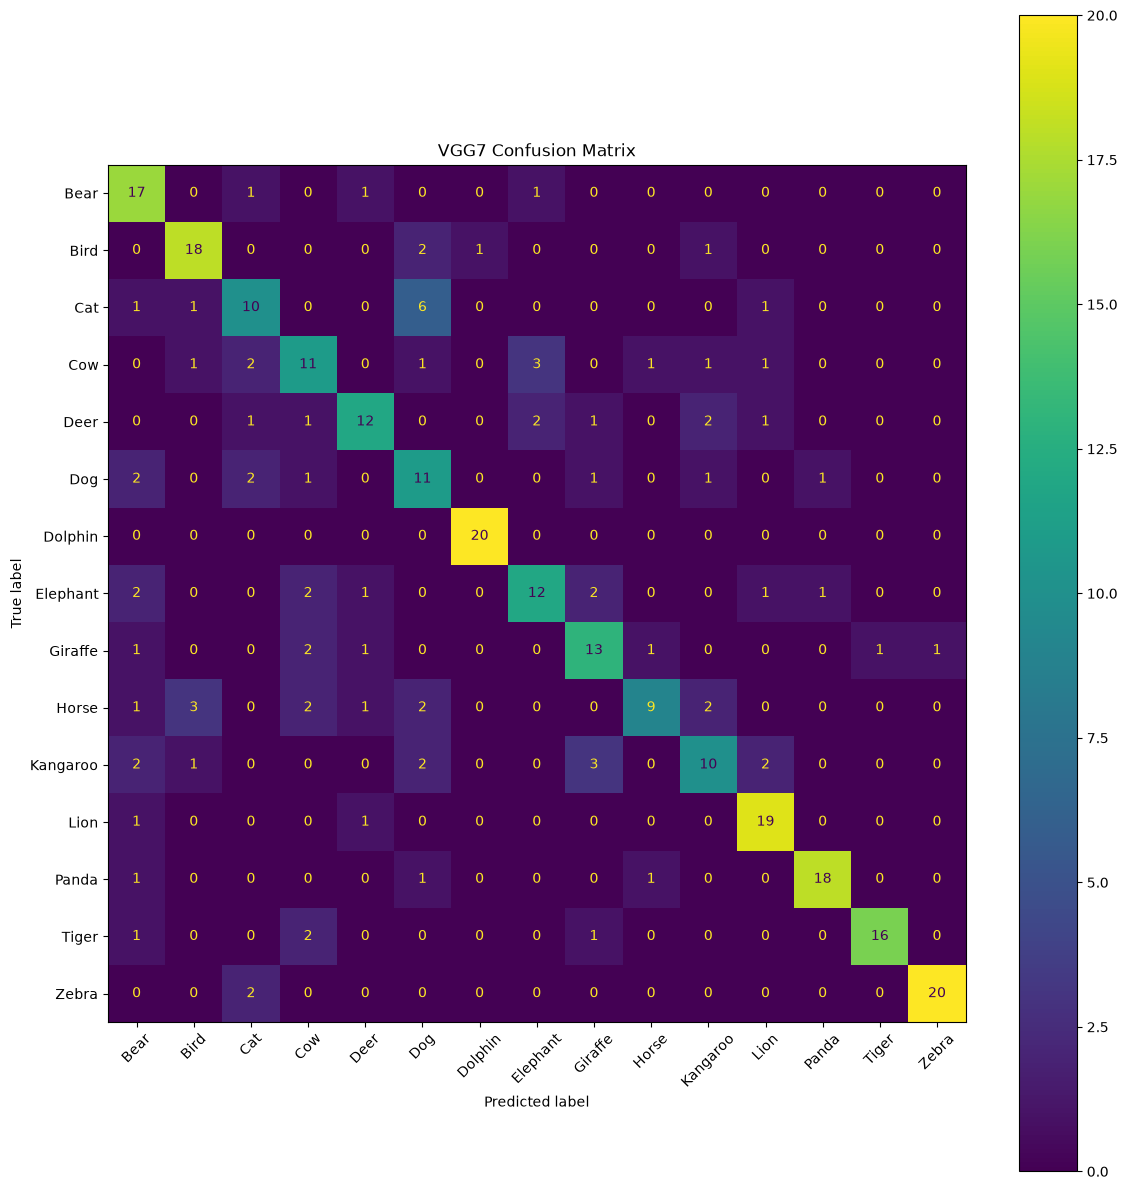

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Make sure the best model is loaded
model.load_state_dict(
    torch.load("vgg7_best.pth", map_location=device)
)

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Create confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

fig, ax = plt.subplots(figsize=(12, 12))
disp.plot(ax=ax, xticks_rotation=45)

plt.title("VGG7 Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    target_names=test_dataset.classes,
    digits=4
))

              precision    recall  f1-score   support

        Bear     0.5862    0.8500    0.6939        20
        Bird     0.7500    0.8182    0.7826        22
         Cat     0.5556    0.5263    0.5405        19
         Cow     0.5238    0.5238    0.5238        21
        Deer     0.7059    0.6000    0.6486        20
         Dog     0.4400    0.5789    0.5000        19
     Dolphin     0.9524    1.0000    0.9756        20
    Elephant     0.6667    0.5714    0.6154        21
     Giraffe     0.6190    0.6500    0.6341        20
       Horse     0.7500    0.4500    0.5625        20
    Kangaroo     0.5882    0.5000    0.5405        20
        Lion     0.7600    0.9048    0.8261        21
       Panda     0.9000    0.8571    0.8780        21
       Tiger     0.9412    0.8000    0.8649        20
       Zebra     0.9524    0.9091    0.9302        22

    accuracy                         0.7059       306
   macro avg     0.7128    0.7026    0.7011       306
weighted avg     0.7160   